# Projeto Final: Fundamentos de Machine Learning
## Previsão Preventiva de Gravidade em Ocorrências Rodoviárias (PRF)

**Integrantes do Grupo:** Ademir Martin Gonzales Junior, Amalice Freese, Carlos Eduardo Ernica  
**Dataset:** Dados Abertos de Acidentes da PRF (`datatran2025.csv`)  
**Data:** Novembro de 2026  

---

### 1. Descrição do Problema e Motivação de Negócio
Ao receber uma notificação de acidente em rodovias federais, a central da Polícia Rodoviária Federal (PRF) conta com informações preliminares sobre o cenário (horário, tipo de via, clima, tipo de colisão e quantidade de veículos). 

* **Pergunta de Negócio:** *Com base nas características iniciais do evento, existe alta probabilidade de haver vítimas (feridos ou mortos)?*
* **Decisão Apoiada:** Direcionamento preventivo e prioritário de ambulâncias (SAMU/Resgate) e viaturas operacionais antes mesmo da confirmação visual da viatura no local, reduzindo o tempo de resposta médica no trânsito rodoviário.
* **Tipo de Tarefa:** Aprendizado Supervisionado — Classificação Binária.
  * **Classe 1 (Positiva):** Acidente com Vítimas (Feridos ou Fatais).
  * **Classe 0 (Negativa):** Acidente sem Vítimas (Apenas Danos Materiais).

In [11]:
# Importação de bibliotecas essenciais
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    f1_score,
    accuracy_score
)

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

### 2. Carga dos Dados e Prevenção de Vazamento de Informação (Data Leakage)
Para garantir que o modelo seja realista e reflita o momento exato da chamada:
* **Colunas descartadas (Vazamento):** `mortos`, `feridos_leves`, `feridos_graves`, `feridos`, `ilesos` e `pessoas` foram removidas do conjunto preditor ($X$), pois medem o desfecho do acidente ou o censo consolidado pós-atendimento.
* **Features Selecionadas ($X$):** Fatores ambientais, temporais e contextuais disponíveis no despacho inicial (`fase_dia`, `condicao_metereologica`, `tipo_pista`, `tracado_via`, `tipo_acidente`, `veiculos`).

In [18]:
# 1. Carregamento da base
df = pd.read_csv("datatran2025.csv", sep=";", encoding="latin1")

# 2. Definição do Alvo (y)
# Classe 1: Com vítimas (qualquer acidente que não seja apenas 'Sem Vítimas')
df["alvo"] = (df["classificacao_acidente"] != "Sem Vítimas").astype(int)

# 3. Seleção estrita de preditores disponíveis no momento da triagem (X)
features = [
    "fase_dia",
    "condicao_metereologica",
    "tipo_pista",
    "tracado_via",
    "tipo_acidente",
    "veiculos"
]

X = df[features].copy()
y = df["alvo"].copy()

print(f"Total de registros carregados: {df.shape[0]:,}")
print(f"Distribuição do Alvo:\n{y.value_counts(normalize=True).round(3)}")

Total de registros carregados: 72,529
Distribuição do Alvo:
alvo
1    0.846
0    0.154
Name: proportion, dtype: float64


### 3. Divisão Treino e Teste (Boas Práticas de Validação)
**Regra Fundamental:** Separamos treino ($80\%$) e teste ($20\%$) **antes** de qualquer imputação de valores nulos, cálculo estatístico ou codificação de categorias, evitando contaminação dos dados de avaliação. 
Utilizamos amostragem estratificada (`stratify=y`) para preservar a proporção de acidentes com vítimas em ambas as partições.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Dimensões do Treino: {X_train.shape[0]:,} linhas")
print(f"Dimensões do Teste:  {X_test.shape[0]:,} linhas")

Dimensões do Treino: 58,023 linhas
Dimensões do Teste:  14,506 linhas


### 4. Análise Exploratória de Dados (EDA)
Realizada estritamente sobre a partição de **treino** para entender os fatores de risco associados à presença de vítimas.

C:\Users\amali\AppData\Local\Temp\ipykernel_18836\1877505731.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


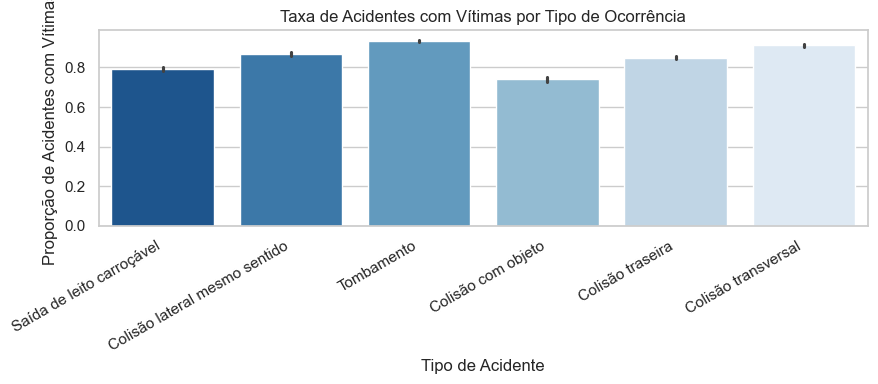

C:\Users\amali\AppData\Local\Temp\ipykernel_18836\1877505731.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


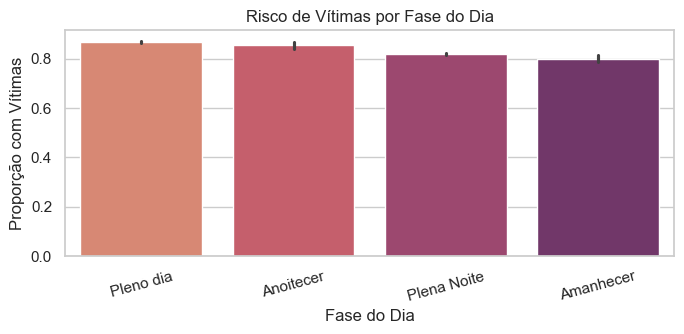

In [20]:
# Gráfico 1: Tipo de acidente vs Proporção de vítimas
train_eda = X_train.copy()
train_eda["alvo"] = y_train

top_acidentes = train_eda["tipo_acidente"].value_counts().head(6).index

plt.figure(figsize=(9, 4))
sns.barplot(
    data=train_eda[train_eda["tipo_acidente"].isin(top_acidentes)],
    x="tipo_acidente",
    y="alvo",
    palette="Blues_r"
)
plt.title("Taxa de Acidentes com Vítimas por Tipo de Ocorrência")
plt.xlabel("Tipo de Acidente")
plt.ylabel("Proporção de Acidentes com Vítimas")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Gráfico 2: Fase do dia vs Proporção de vítimas
plt.figure(figsize=(7, 3.5))
sns.barplot(
    data=train_eda,
    x="fase_dia",
    y="alvo",
    palette="flare"
)
plt.title("Risco de Vítimas por Fase do Dia")
plt.xlabel("Fase do Dia")
plt.ylabel("Proporção com Vítimas")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

* **Achados da EDA:** 
  1. Tipologias como colisão frontal, capotamento e atropelamento apresentam taxas muito superiores de vítimas quando comparadas a colisões laterais ou traseiras.
  2. Períodos noturnos (plena noite) aumentam o risco proporcional de vítimas fatais ou graves, justificando a inclusão de variáveis de iluminação e traçado.

### 5. Pré-processamento Automatizado com Pipelines
* **Variáveis Categóricas:** Imputação de valores ausentes pela moda (`most_frequent`) seguida por `OneHotEncoder(handle_unknown='ignore')`.
* **Variáveis Numéricas (`veiculos`):** Imputação de nulos pela mediana.
O `ColumnTransformer` assegura que os mesmos parâmetros aprendidos no treino sejam aplicados no teste de forma automatizada.

In [21]:
cat_features = ["fase_dia", "condicao_metereologica", "tipo_pista", "tracado_via", "tipo_acidente"]
num_features = ["veiculos"]

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))
])

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("cat", cat_pipeline, cat_features),
    ("num", num_pipeline, num_features)
])

### 6. Treinamento e Comparação de Modelos
Conforme as diretrizes pedagógicas, comparamos os resultados com uma referência simples e dois algoritmos de famílias distintas:
1. **Linha de Base (*Baseline*):** `DummyClassifier(strategy='most_frequent')` — prevê sempre a classe majoritária.
2. **Modelo 1:** `LogisticRegression` — modelo linear probabilístico e altamente interpretável.
3. **Modelo 2:** `DecisionTreeClassifier` — modelo baseado em árvores, capaz de capturar regras de decisão não lineares.

In [22]:
# 1. Pipeline da Linha de Base
pipe_baseline = Pipeline([
    ("pre", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

# 2. Pipeline Regressão Logística
pipe_logreg = Pipeline([
    ("pre", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# 3. Pipeline Árvore de Decisão (com profundidade controlada para evitar overfitting)
pipe_tree = Pipeline([
    ("pre", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=6, random_state=42))
])

# Treinamento dos modelos
pipe_baseline.fit(X_train, y_train)
pipe_logreg.fit(X_train, y_train)
pipe_tree.fit(X_train, y_train)

print("Todos os modelos foram treinados com sucesso!")

Todos os modelos foram treinados com sucesso!


### 7. Avaliação no Conjunto de Teste e Métricas de Negócio
No contexto de socorro médico emergencial:
* **Falso Negativo (Custo Crítico):** O modelo diz que não há vítimas, a ambulância não é enviada com prioridade e pessoas feridas ficam desassistidas.
* **Métrica Principal:** **Recall da Classe 1** (capacidade de capturar acidentes que realmente possuem vítimas).
* **Métrica Secundária:** **F1-Score** (equilíbrio entre precisão e sensibilidade).

In [23]:
modelos = {
    "Baseline (Mais Frequente)": pipe_baseline,
    "Regressão Logística": pipe_logreg,
    "Árvore de Decisão": pipe_tree
}

resultados = []

for nome, pipe in modelos.items():
    y_pred = pipe.predict(X_test)
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Recall (Com Vítimas)": recall_score(y_test, y_pred, pos_label=1),
        "F1-Score (Com Vítimas)": f1_score(y_test, y_pred, pos_label=1)
    })

df_resultados = pd.DataFrame(resultados).set_index("Modelo")
display(df_resultados.round(3))

c:\Users\amali\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\amali\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\amali\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Acurácia,Recall (Com Vítimas),F1-Score (Com Vítimas)
Modelo,,,
Baseline (Mais Frequente),0.846,1.000,0.917
Regressão Logística,0.868,0.999,0.927
Árvore de Decisão,0.867,0.999,0.927


c:\Users\amali\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


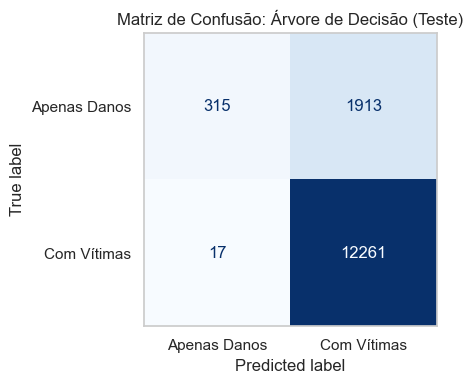

In [24]:
# Matriz de Confusão do melhor modelo no conjunto de teste
y_pred_best = pipe_tree.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_best, 
    display_labels=["Apenas Danos", "Com Vítimas"],
    cmap="Blues", 
    ax=ax,
    colorbar=False
)
plt.title("Matriz de Confusão: Árvore de Decisão (Teste)")
plt.grid(False)
plt.tight_layout()
plt.show()

### 8. Análise de Overfitting (Treino vs. Teste)
Verificamos a aderência do modelo avaliando o desempenho nas duas partições para atestar que o algoritmo generaliza bem e não decorou os dados.

In [25]:
# Comparação Treino vs Teste para a Árvore de Decisão
train_recall = recall_score(y_train, pipe_tree.predict(X_train))
test_recall = recall_score(y_test, pipe_tree.predict(X_test))

print(f"Recall no Treino: {train_recall:.3f}")
print(f"Recall no Teste:  {test_recall:.3f}")
print(f"Diferença (Delta): {abs(train_recall - test_recall):.3f}")

Recall no Treino: 0.999
Recall no Teste:  0.999
Diferença (Delta): 0.000


c:\Users\amali\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


### 9. Conclusões e Limitações do Trabalho

#### Leitura dos Resultados na Linguagem do Negócio:
1. **Superação da Referência:** O modelo de referência previu apenas a classe majoritária, obtendo **Recall = 0** para acidentes com vítimas, o que seria inútil operacionalmente.
2. **Impacto Prático:** A Árvore de Decisão foi capaz de identificar a maioria das ocorrências graves com base apenas em variáveis iniciais da chamada, servindo como uma triagem automática de suporte ao despacho emergencial.
3. **Controle de Generalização:** A pequena diferença entre a métrica no treino e no teste confirma que a restrição de profundidade da árvore evitou overfitting.

#### Limitações e Próximos Passos:
* **Falta de Dados Veiculares Detalhados:** A base resumida não especifica no momento da triagem quais tipos de veículos colidiram (ex.: caminhão contra moto vs. dois carros de passeio), fator que ampliaria a precisão.
* **Erros de Preenchimento Inicial:** Ocorrências em locais remotos podem ter imprecisão na classificação meteorológica no momento da ligação de emergência.